#### Time sampling for the KdV symbol: how large can the gaps between snapshots be?

KdV has the symbol $m(k)=1-k^2/6$ and $n=1/2$.
The waves are simulated with a fine time step `dt`, and then only every `stride`-th snapshot is given to the LSM, so the time derivative is estimated from snapshots that are `stride*dt` apart.

Since $m(k)$ crosses zero at $k=\sqrt6$, a relative error in $\hat\ell$ is meaningless near there, so **absolute errors** $|\hat\ell-\ell|$ and $|\hat n-n|$ are used throughout.

In [12]:
import sys
from pathlib import Path

root = Path.cwd().parent.parent
sys.path.insert(0,str(root))

from camera.camera_file import Camera
from camera.spectralCamera import *
from camera.pdeCamera import *
from camera.lsmCamera import LSM
from solvers.help import *

from waves.waveGenCamera import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [13]:
# Wave set-up

L   = 2*2*np.pi
N   = 2**7
dt  = 5e-4
c1  = Camera(L, N, dt)
T   = 0.5

amps  = np.linspace(0.5, 2, 4)
means = np.zeros_like(amps)
ps    = L*np.ones_like(amps)

In [14]:
kdvp = KdVPacket(ps, amps, means, c1, T)
H = np.array(kdvp.mainloop())
print(H.shape)          # (waves, time snapshots, x)

(4, 1001, 128)


In [15]:
# Strides to look at (stride 1 = every snapshot, the reference)
MIN_SNAP   = 8      # snapshots per wave needed (time-derivative stencil + a few usable samples)
max_stride = 20
step    = np.arange(2, max_stride + 1, 2)
strides = np.concatenate([[1], step]).astype(int)
# drop strides that leave too few snapshots
strides = np.array([s for s in strides if len(range(0, H.shape[1], s)) >= MIN_SNAP])
print("strides used:", strides)

strides used: [ 1  2  4  6  8 10 12 14 16 18 20]


In [16]:
# Subsample in time
h_list = [H[:, ::s, :] for s in strides]

For each stride the LSM is run on a camera whose time step is `stride*dt`, which is what the finite-difference time derivative sees. (This is equivalent to passing `stride=` to the LSM and does not need that argument.)

In [17]:
lsmlist = []
for s, h in zip(strides, h_list):
    cam_s = Camera(L, N, dt*s)
    lsm = LSM(eta_list=h, camera=cam_s)
    lsm.lsm()
    lsmlist.append(lsm)

In [18]:
# Positive wavenumbers (k = 0 is NaN in the LSM), ascending
k_all = c1.k
pos   = np.where(k_all > 0)[0]
pos   = pos[np.argsort(k_all[pos])]
kp    = k_all[pos]

ell_th = kdVDispersion(kp)
n_th   = n_theory(kp)

ell_s = [l.ell[pos].real for l in lsmlist]
n_s   = [l.n[pos].real   for l in lsmlist]

def label(i):
    return f"stride {strides[i]}, {h_list[i].shape[1]} snapshots/wave"


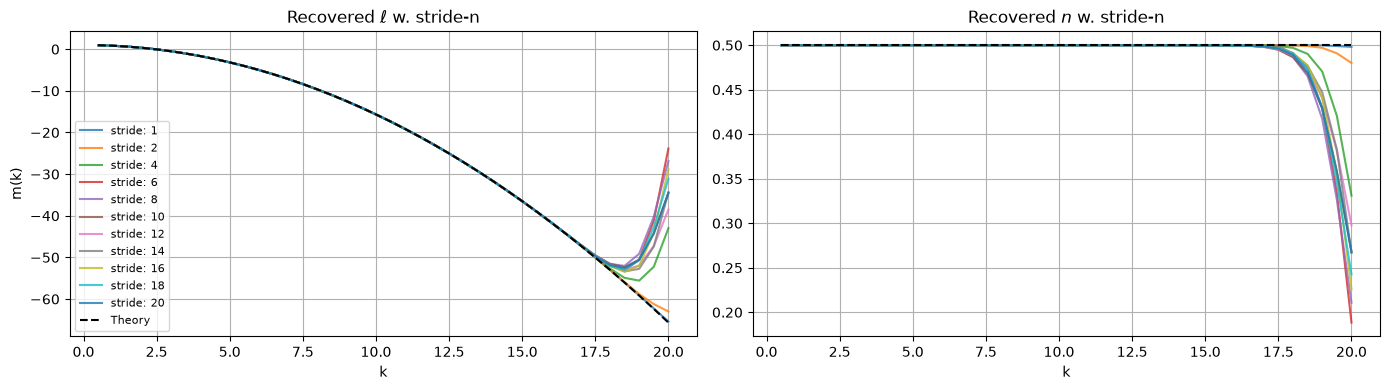

In [19]:
K_PLOT = 20
m = kp <= K_PLOT

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for i in range(len(strides)):
    ax[0].plot(kp[m], ell_s[i][m], alpha=0.8, label=f"stride: {strides[i]}")
    ax[1].plot(kp[m], n_s[i][m],   alpha=0.8, label=f"stride: {strides[i]}")
ax[0].plot(kp[m], ell_th[m], 'k--', label="Theory")
ax[1].plot(kp[m], n_th[m],   'k--', label="Theory")
ax[0].set_title(r"Recovered $\ell$ w. stride-n"); ax[1].set_title(r"Recovered $n$ w. stride-n")
for a in ax:
    a.set_xlabel("k"); a.grid(True)
ax[0].set_ylabel("m(k)")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

Does the stride only matter once the recovered symbol has already left the true symbol, as it did for KdV? The error plots below quantify this.

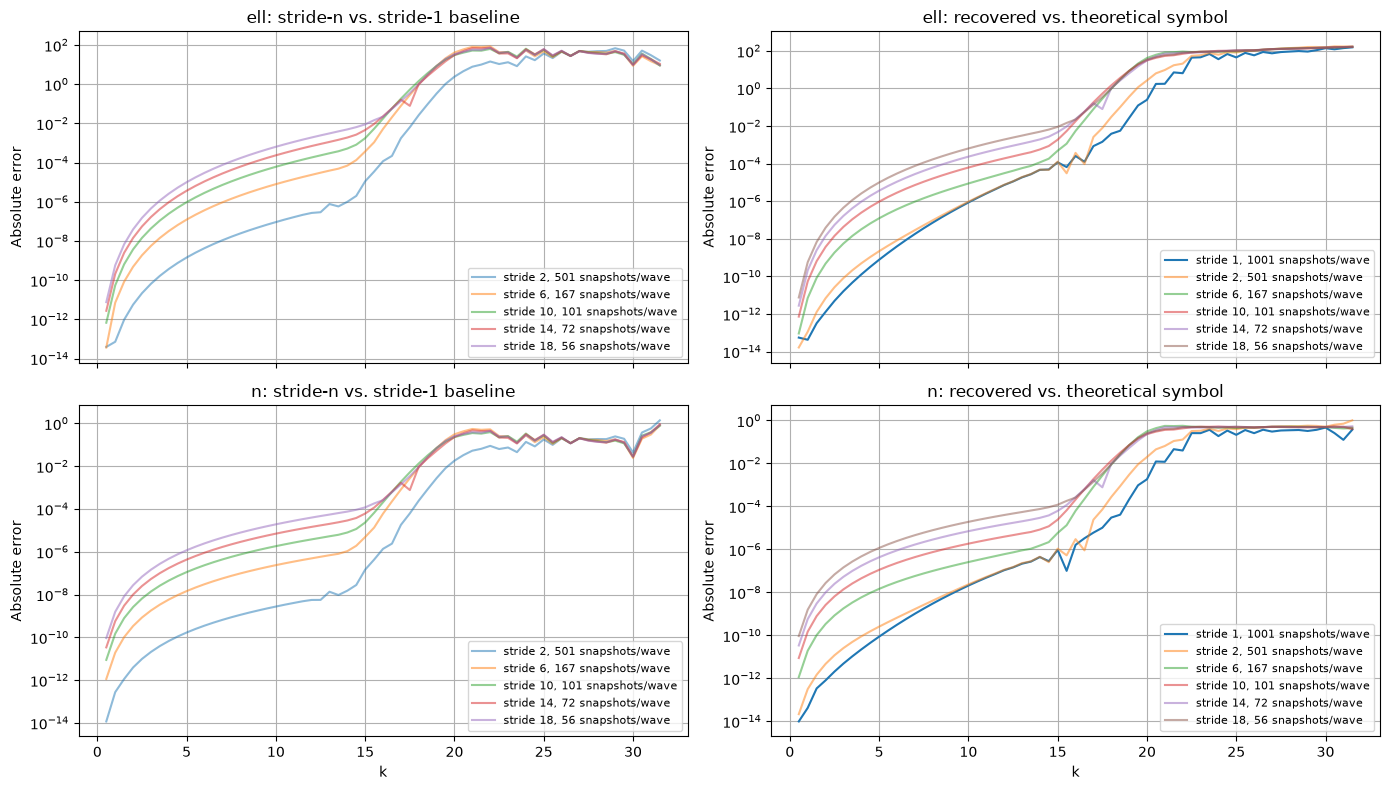

In [20]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

for row, (name, rec, th) in enumerate([("ell", ell_s, ell_th), ("n", n_s, n_th)]):
    ref_num = rec[0]
    # stride-1 against theory
    ax[row, 1].semilogy(kp, np.abs(ref_num - th), label=label(0))
    for i in range(1, len(strides), 2):
        # absolute error vs. the stride-1 baseline
        ax[row, 0].semilogy(kp, np.abs(rec[i] - ref_num), alpha=0.5, label=label(i))
        # absolute error vs. theoretical symbol
        ax[row, 1].semilogy(kp, np.abs(rec[i] - th), alpha=0.5, label=label(i))
    ax[row, 0].set_title(f"{name}: stride-n vs. stride-1 baseline")
    ax[row, 1].set_title(f"{name}: recovered vs. theoretical symbol")
    for a in ax[row]:
        a.set_ylabel("Absolute error"); a.grid(True, which='both')
        a.legend(loc="lower right", fontsize=8)
for a in ax[1]: a.set_xlabel("k")
plt.tight_layout(); plt.show()

#### How far out in $k$ is the symbol accurate, as a function of stride?

$k^*(\mathrm{tol})$ is the largest $k$ such that the absolute error against theory is below `tol` for *every* $0<k\le k^*$.

In [21]:
TOLS = [1e-1, 1e-2, 1e-3]

def cutoff(err, tol):
    # largest k* with err <= tol for all 0 < k <= k*  (NaN counts as failing)
    bad = ~(err <= tol)
    if not bad.any():
        return kp[-1]
    i = np.argmax(bad)
    return kp[i-1] if i > 0 else 0.0

rows = []
for i, s in enumerate(strides):
    e_ell = np.abs(ell_s[i] - ell_th)
    e_n   = np.abs(n_s[i]   - n_th)
    row = {"stride": s, "dt_eff": dt*s}
    for tol in TOLS:
        row[f"k*_ell ({tol:g})"] = cutoff(e_ell, tol)
        row[f"k*_n ({tol:g})"]   = cutoff(e_n,   tol)
    rows.append(row)
kstar = pd.DataFrame(rows).set_index("stride")
print(f"Nyquist k = {kp[-1]:.2f}")
kstar

Nyquist k = 31.50


,dt_eff,k*_ell (0.1),k*_n (0.1),k*_ell (0.01),k*_n (0.01),k*_ell (0.001),k*_n (0.001)
stride,,,,,,,
1,0.0005,19.0,22.0,18.5,20.0,17.0,19.5
2,0.0010,18.0,21.0,17.5,19.5,16.5,18.5
4,0.0020,17.5,19.5,16.5,18.5,15.5,17.5
6,0.0030,17.0,19.0,16.0,18.0,15.0,17.0
8,0.0040,16.5,19.0,15.5,17.5,14.5,16.5
10,0.0050,16.5,19.0,15.5,17.5,14.5,16.5
12,0.0060,16.5,19.0,15.5,17.5,13.5,16.5
14,0.0070,16.5,19.0,15.5,18.0,12.5,16.5
16,0.0080,16.5,19.0,15.0,18.0,11.5,16.5


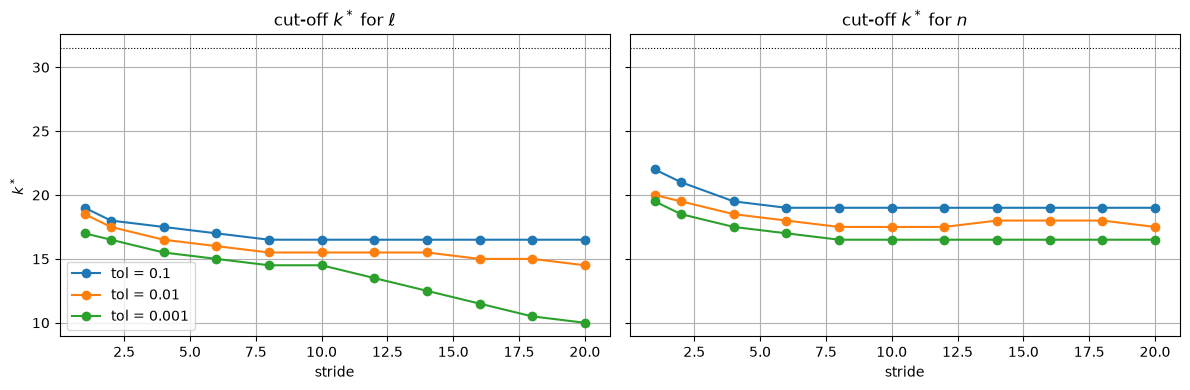

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for tol in TOLS:
    ax[0].plot(kstar.index, kstar[f"k*_ell ({tol:g})"], 'o-', label=f"tol = {tol:g}")
    ax[1].plot(kstar.index, kstar[f"k*_n ({tol:g})"],   'o-', label=f"tol = {tol:g}")
ax[0].set_title(r"cut-off $k^*$ for $\ell$"); ax[1].set_title(r"cut-off $k^*$ for $n$")
for a in ax:
    a.axhline(kp[-1], color='k', ls=':', lw=0.8)
    a.set_xlabel("stride"); a.grid(True)
ax[0].set_ylabel("$k^*$"); ax[0].legend()
plt.tight_layout(); plt.show()